In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib

print("All libraries are ready!")
print("Scikit-learn:", sklearn.__version__)

All libraries are ready!
Scikit-learn: 1.7.2


In [71]:
# Load the original dataset
df = pd.read_csv("Crop_recommendation.csv")

# Display dataset information
print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display first five records
display(df.head())

Dataset loaded successfully!
Number of rows: 2200
Number of columns: 8


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [72]:
# Display all column names
print("Columns:")
print(df.columns.tolist())

# Dataset information
df.info()

# Statistical summary
display(df.describe())

Columns:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [73]:
# Check missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Total missing values
print("\nTotal missing values:", df.isnull().sum().sum())

Missing values:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Total missing values: 0


In [74]:
print("Number of duplicate rows:", df.duplicated().sum())
crop_counts = df["label"].value_counts()

print(crop_counts)
print("\nNumber of crop classes:", df["label"].nunique())

Number of duplicate rows: 0
label
rice           100
maize          100
jute           100
cotton         100
coconut        100
papaya         100
orange         100
apple          100
muskmelon      100
watermelon     100
grapes         100
mango          100
banana         100
pomegranate    100
lentil         100
blackgram      100
mungbean       100
mothbeans      100
pigeonpeas     100
kidneybeans    100
chickpea       100
coffee         100
Name: count, dtype: int64

Number of crop classes: 22


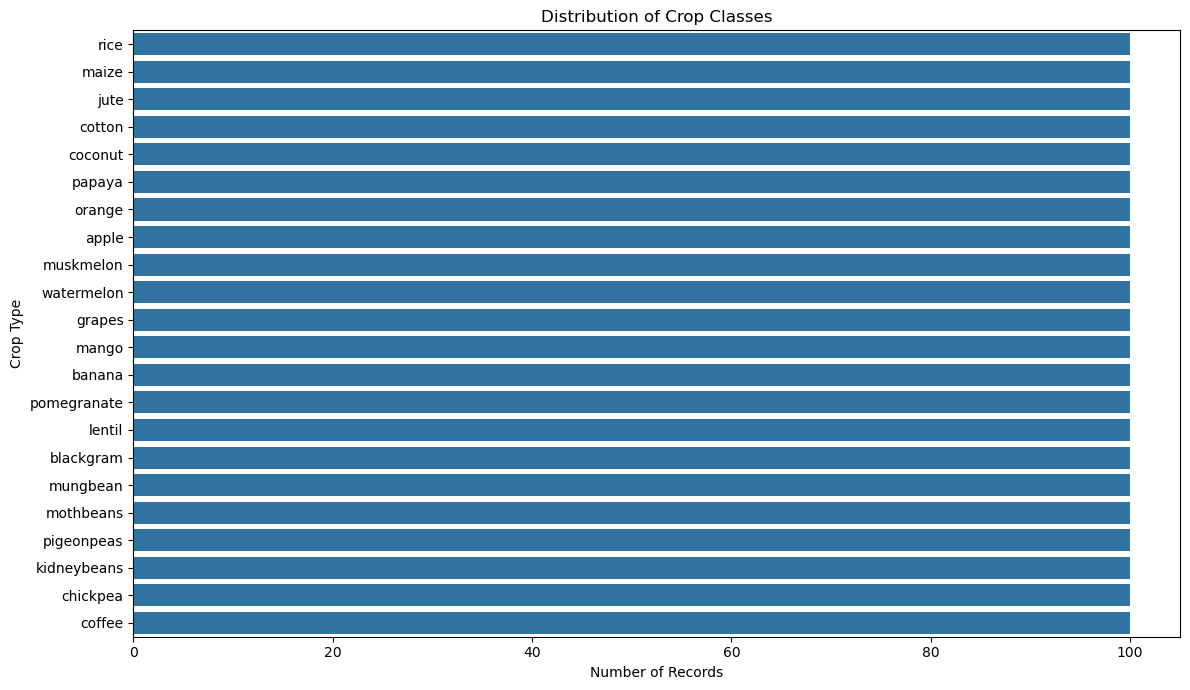

In [75]:
plt.figure(figsize=(12, 7))

sns.countplot(
    data=df,
    y="label",
    order=df["label"].value_counts().index
)

plt.title("Distribution of Crop Classes")
plt.xlabel("Number of Records")
plt.ylabel("Crop Type")

plt.tight_layout()
plt.show()

In [76]:
numerical_features = [
    "N", "P", "K",
    "temperature", "humidity",
    "ph", "rainfall"
]

display(df[numerical_features].describe())

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


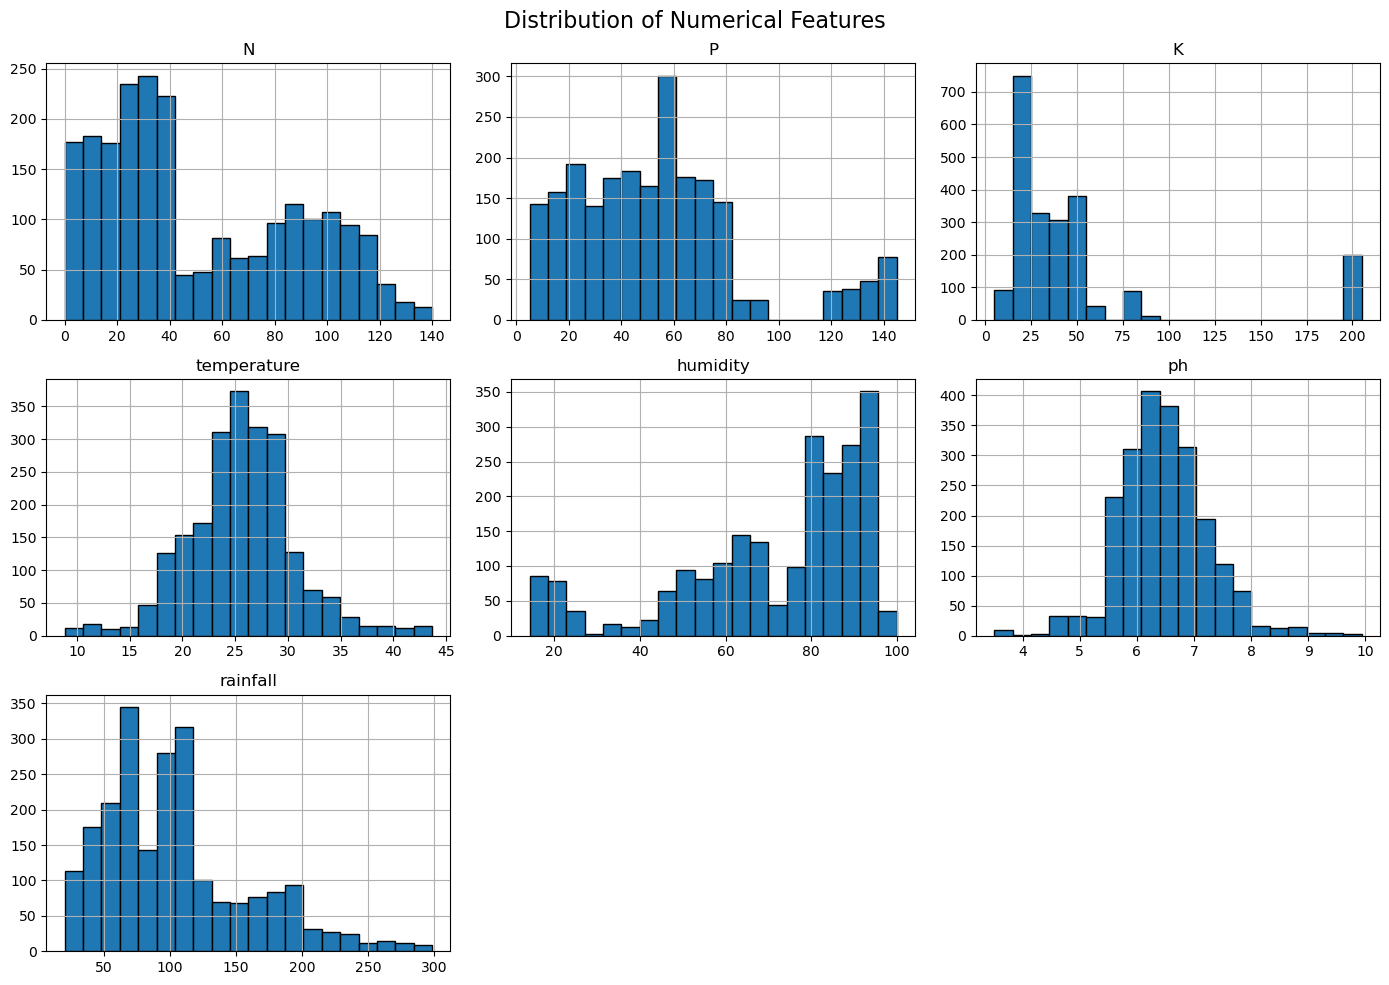

In [77]:
df[numerical_features].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

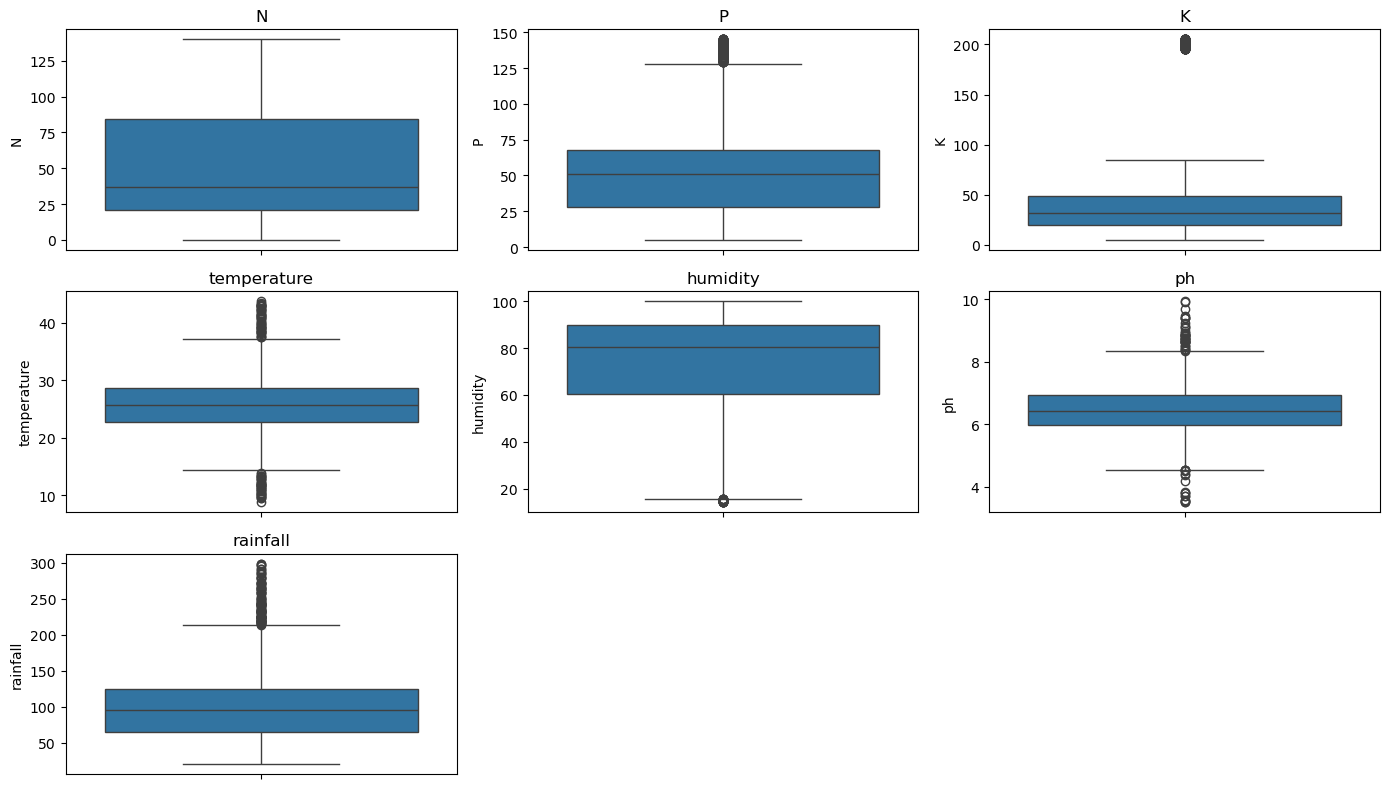

In [78]:
plt.figure(figsize=(14, 8))

for i, col in enumerate(numerical_features, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

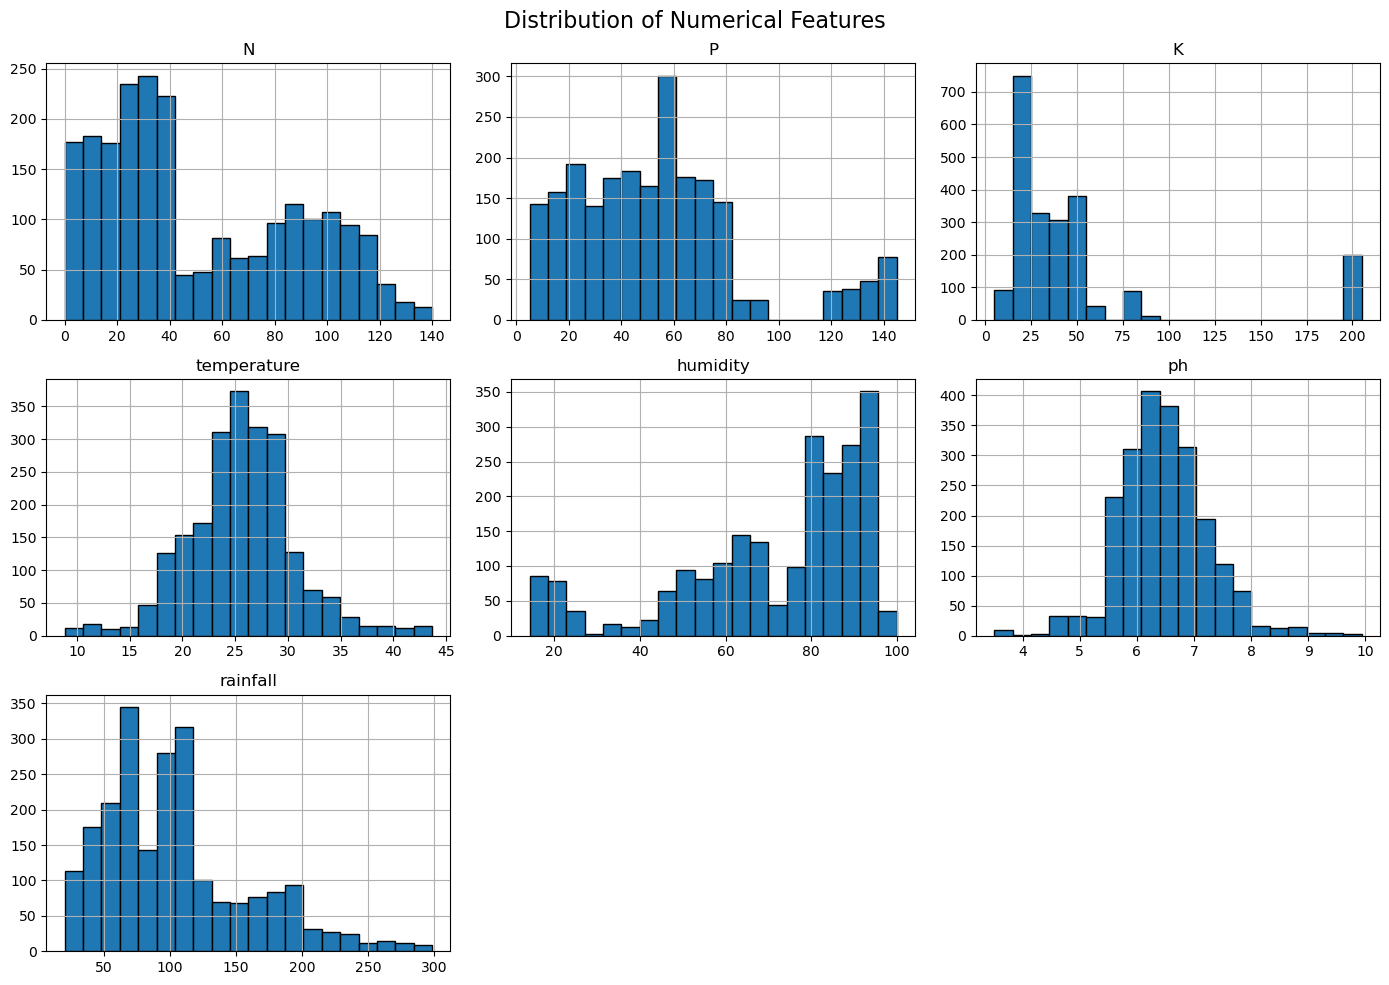

In [79]:
numerical_features = [
    "N", "P", "K",
    "temperature", "humidity",
    "ph", "rainfall"
]

df[numerical_features].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

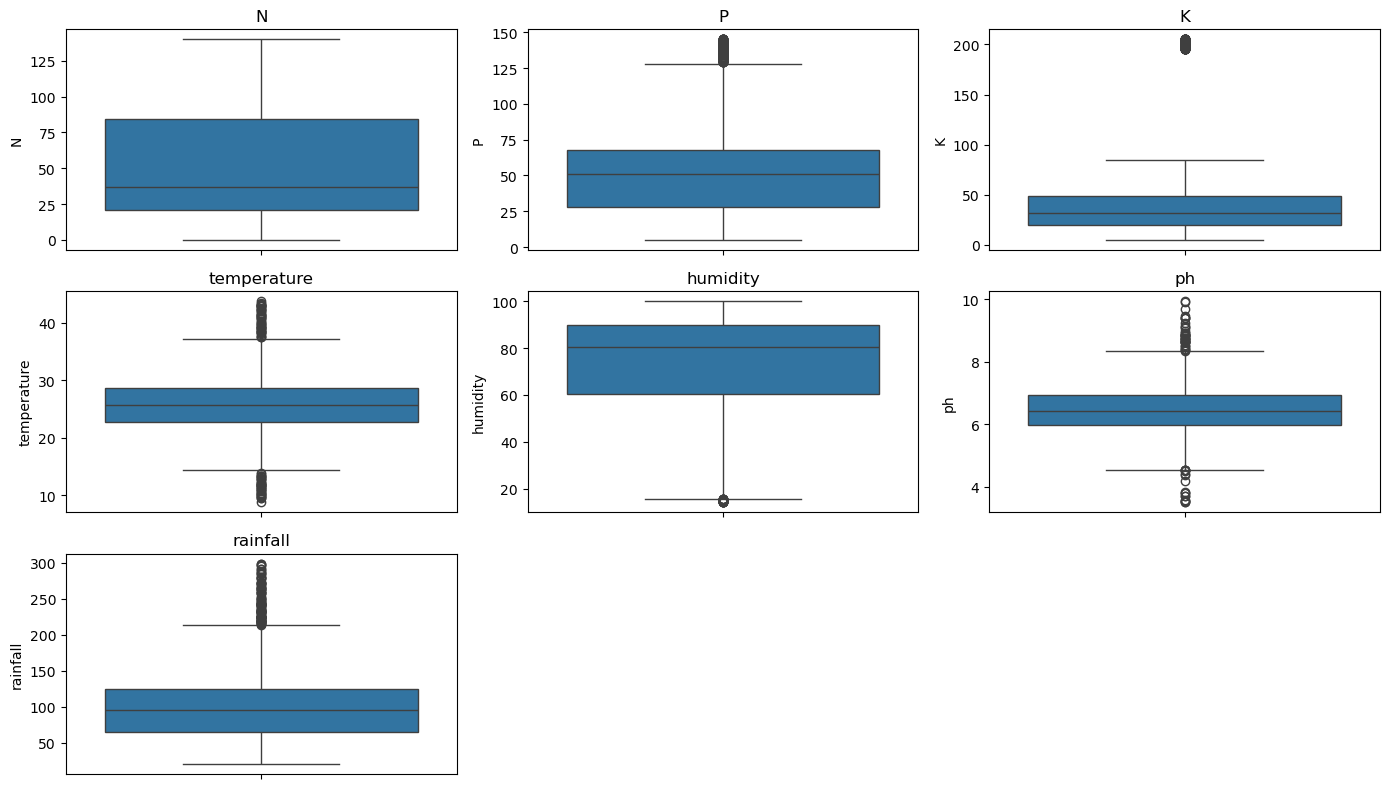

In [80]:
plt.figure(figsize=(14, 8))

for i, col in enumerate(numerical_features, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

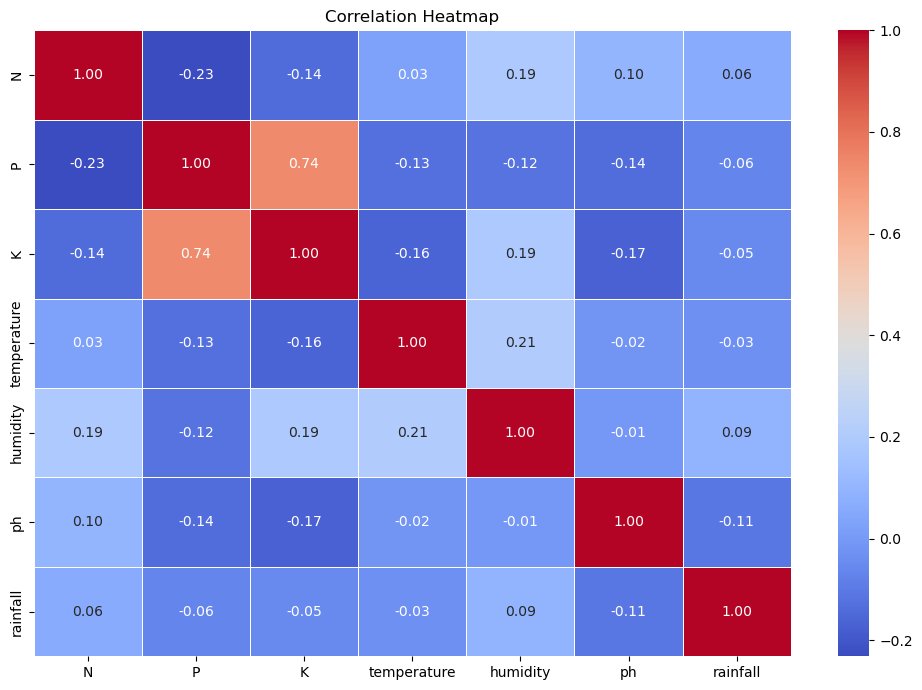

In [81]:
# Calculate correlation
correlation = df[numerical_features].corr()

# Plot heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

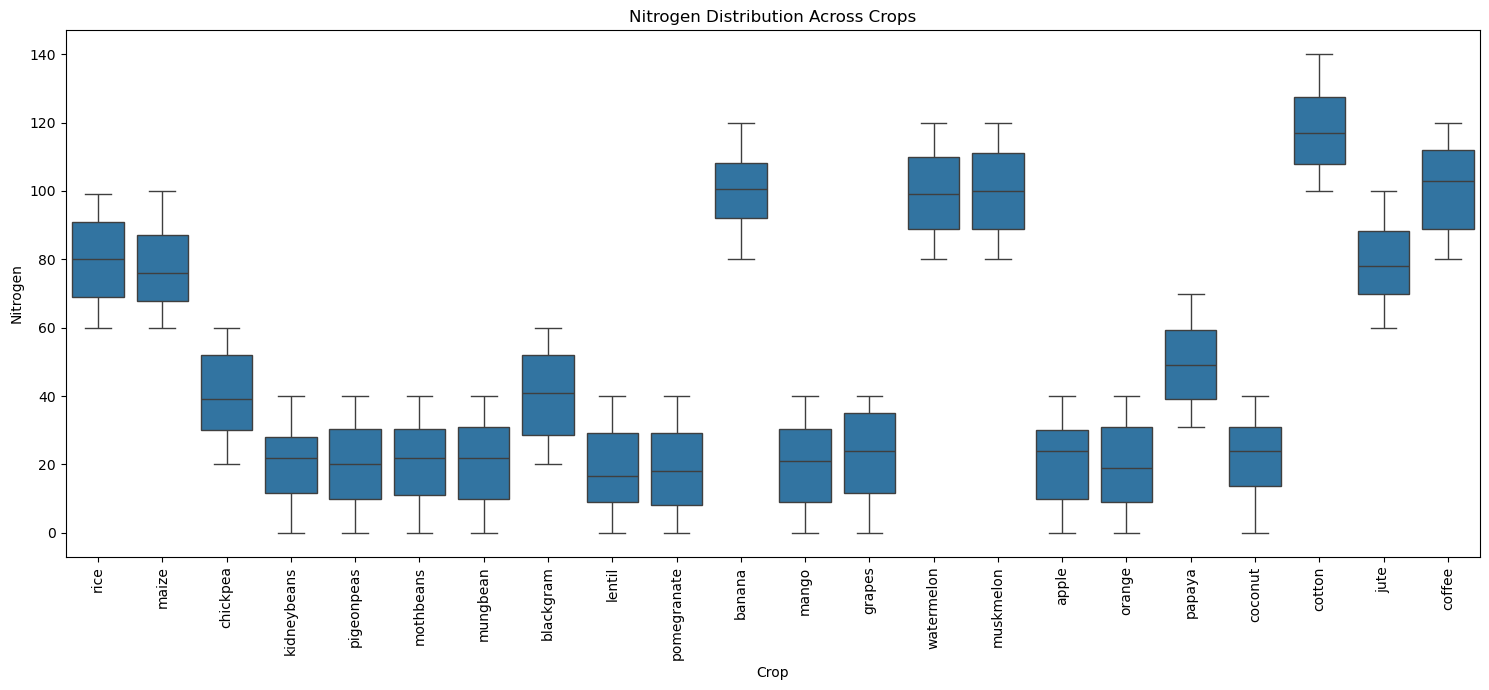

In [82]:
plt.figure(figsize=(15, 7))

sns.boxplot(
    data=df,
    x="label",
    y="N"
)

plt.xticks(rotation=90)
plt.title("Nitrogen Distribution Across Crops")
plt.xlabel("Crop")
plt.ylabel("Nitrogen")
plt.tight_layout()
plt.show()

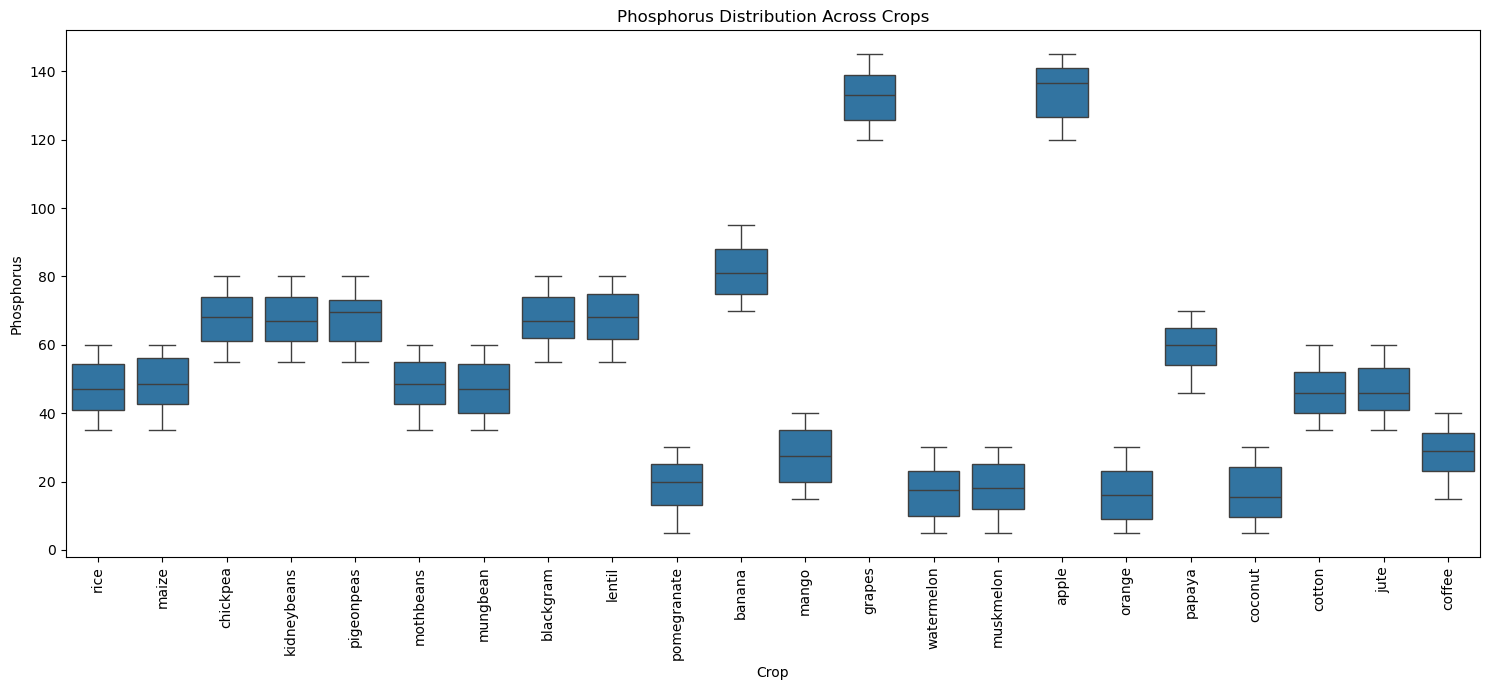

In [83]:
# Phosphorus distribution across crops

plt.figure(figsize=(15, 7))

sns.boxplot(
    data=df,
    x="label",
    y="P"
)

plt.xticks(rotation=90)
plt.title("Phosphorus Distribution Across Crops")
plt.xlabel("Crop")
plt.ylabel("Phosphorus")

plt.tight_layout()
plt.show()

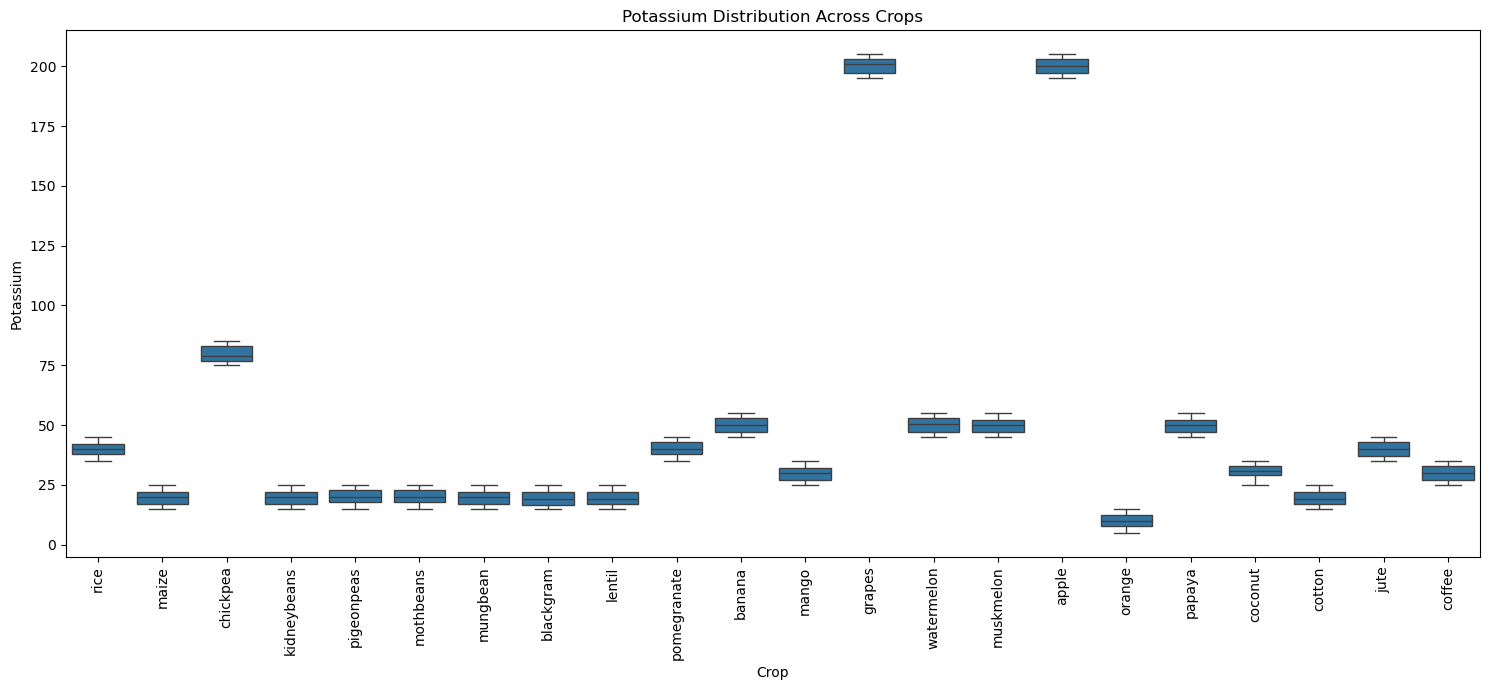

In [84]:
# Potassium distribution across crops

plt.figure(figsize=(15, 7))

sns.boxplot(
    data=df,
    x="label",
    y="K"
)

plt.xticks(rotation=90)
plt.title("Potassium Distribution Across Crops")
plt.xlabel("Crop")
plt.ylabel("Potassium")

plt.tight_layout()
plt.show()

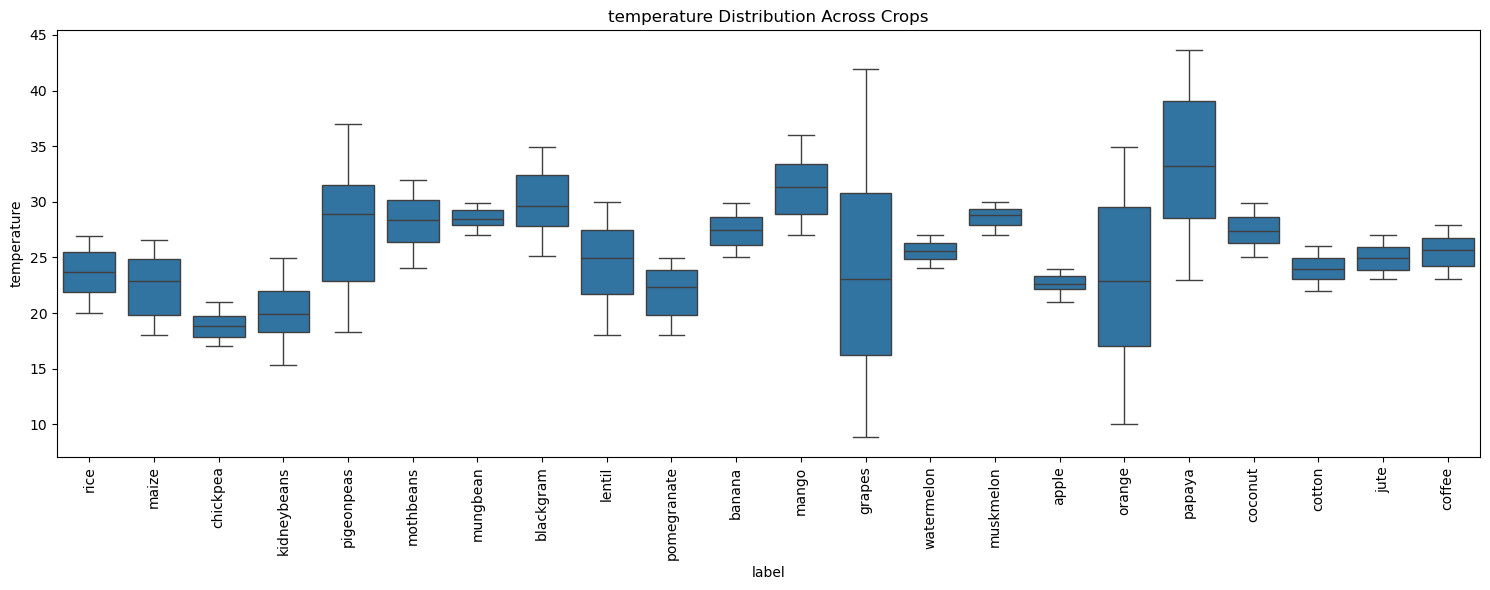

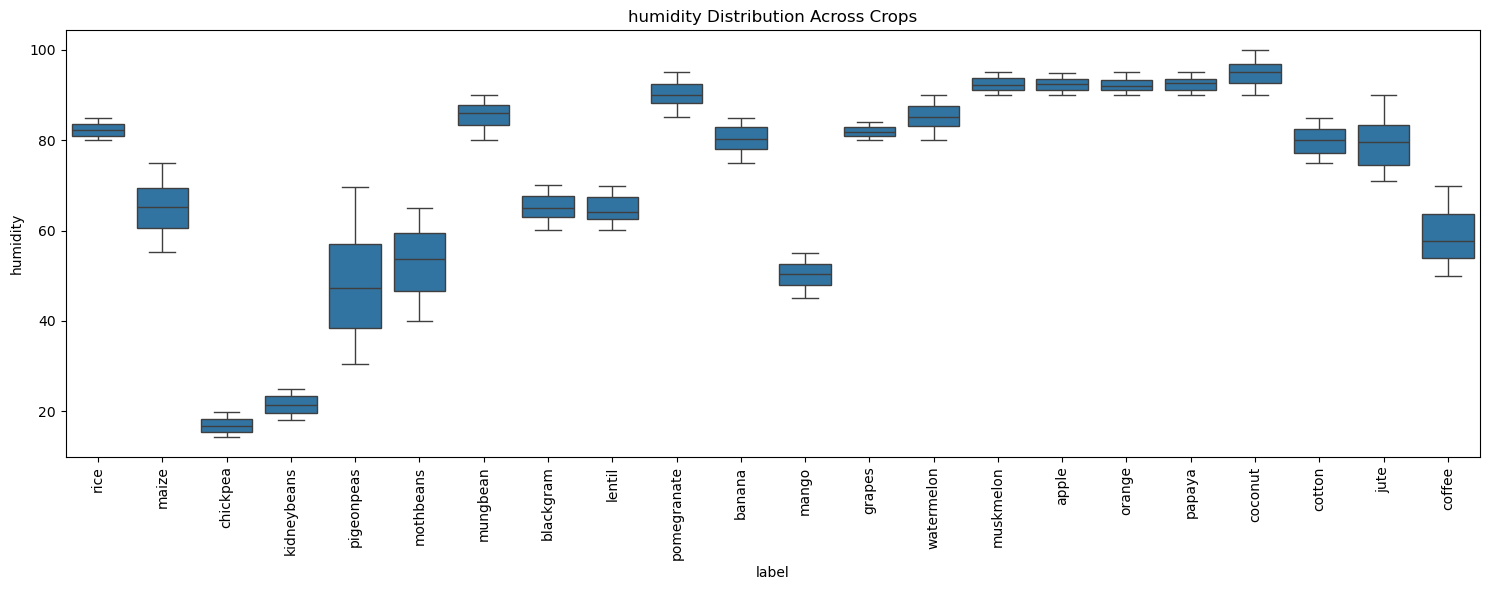

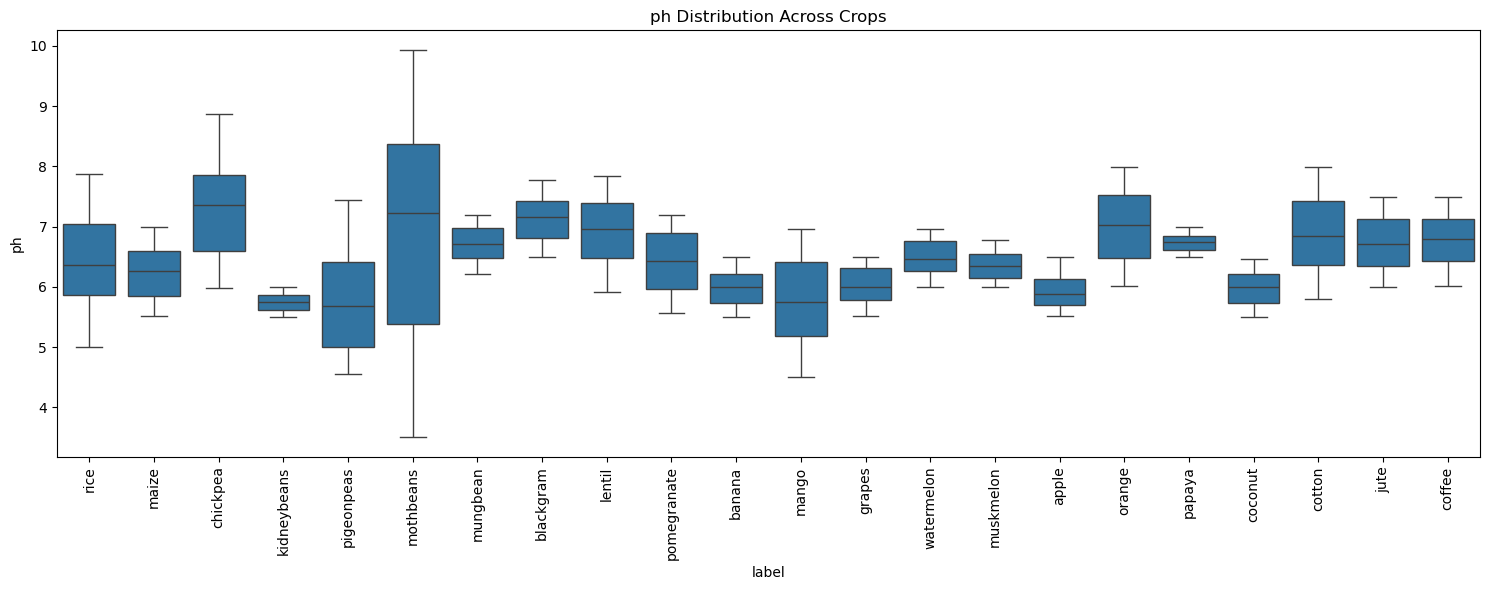

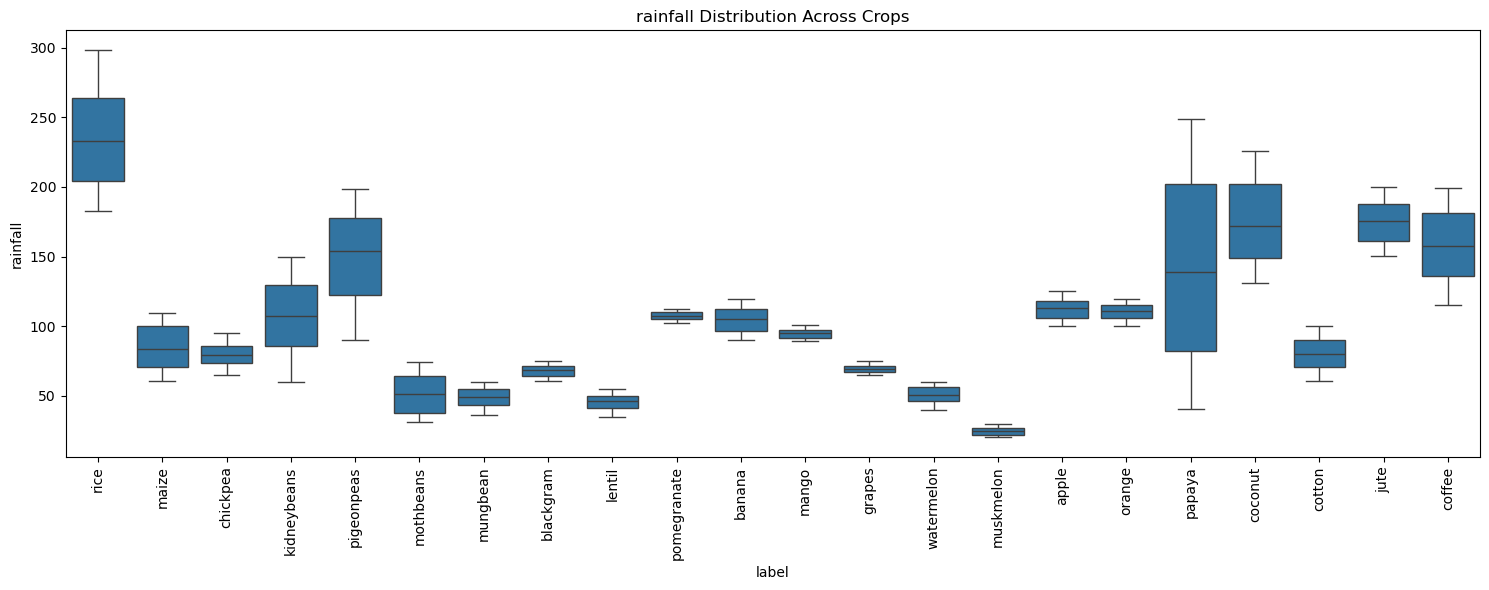

In [85]:
environment_features = [
    "temperature",
    "humidity",
    "ph",
    "rainfall"
]

for feature in environment_features:

    plt.figure(figsize=(15, 6))

    sns.boxplot(
        data=df,
        x="label",
        y=feature
    )

    plt.xticks(rotation=90)
    plt.title(f"{feature} Distribution Across Crops")

    plt.tight_layout()
    plt.show()

In [86]:
print(df.dtypes)

N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label           object
dtype: object


In [87]:
# Independent variables
X = df.drop("label", axis=1)

# Dependent variable
y = df["label"]

print("Input features:", X.columns.tolist())
print("Input shape:", X.shape)

print("\nTarget shape:", y.shape)
print("Crop classes:", y.nunique())

Input features: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
Input shape: (2200, 7)

Target shape: (2200,)
Crop classes: 22


In [88]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Original crop names:")
print(y.head())

print("\nEncoded crop values:")
print(y_encoded[:10])

print("\nCrop mapping:")

for crop, number in zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
):
    print(crop, ":", number)

Original crop names:
0    rice
1    rice
2    rice
3    rice
4    rice
Name: label, dtype: object

Encoded crop values:
[20 20 20 20 20 20 20 20 20 20]

Crop mapping:
apple : 0
banana : 1
blackgram : 2
chickpea : 3
coconut : 4
coffee : 5
cotton : 6
grapes : 7
jute : 8
kidneybeans : 9
lentil : 10
maize : 11
mango : 12
mothbeans : 13
mungbean : 14
muskmelon : 15
orange : 16
papaya : 17
pigeonpeas : 18
pomegranate : 19
rice : 20
watermelon : 21


In [89]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (1760, 7)
Testing data: (440, 7)
Training target: (1760,)
Testing target: (440,)


In [90]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import accuracy_score
import pandas as pd

# Define models
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf"))
    ]),

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000))
    ])
}

# Train and evaluate each model
results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    results.append({
        "Model": name,
        "Accuracy": round(accuracy * 100, 2)
    })

    print(name, ":", round(accuracy * 100, 2), "%")

# Display comparison
results_df = pd.DataFrame(results)

print("\nModel Comparison:")
display(results_df.sort_values(
    by="Accuracy",
    ascending=False
))


Random Forest : 99.55 %
Decision Tree : 97.95 %
KNN : 97.95 %
SVM : 98.41 %
Logistic Regression : 97.27 %

Model Comparison:


,Model,Accuracy
0,Random Forest,99.55
3,SVM,98.41
1,Decision Tree,97.95
2,KNN,97.95
4,Logistic Regression,97.27


Classification Report:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
    

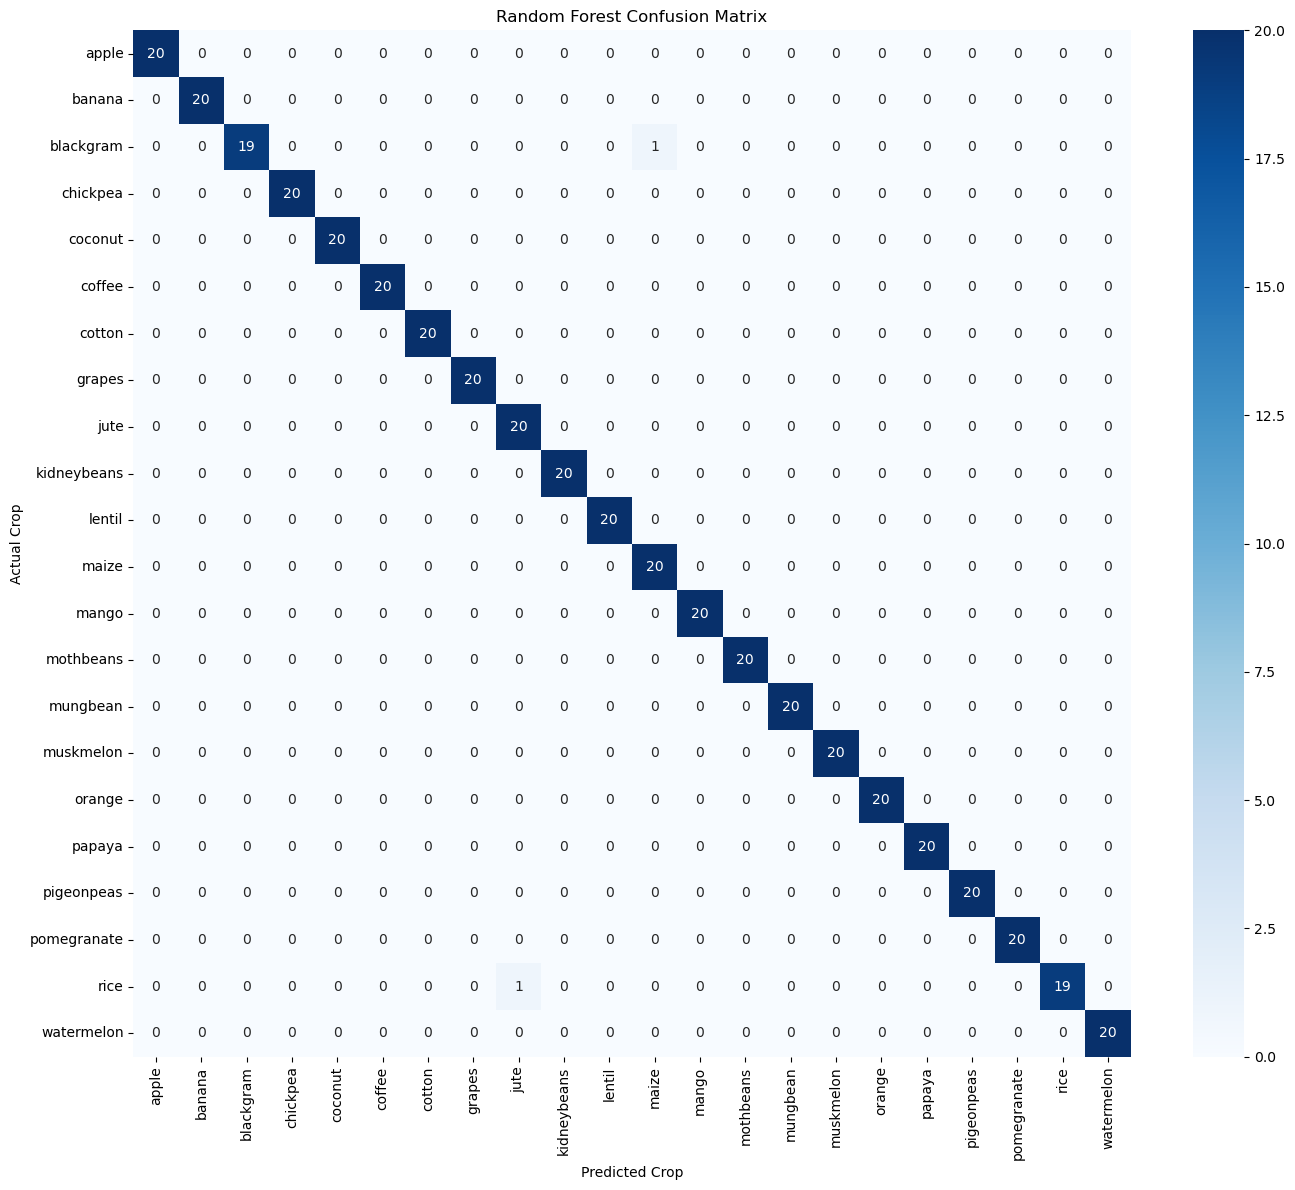

In [91]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Select the best model
best_model = models["Random Forest"]

# Predict test data
y_pred = best_model.predict(X_test)

# Classification report
print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_
    )
)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(14, 12))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [92]:
from sklearn.model_selection import cross_val_score

# Perform 5-fold cross-validation
cv_scores = cross_val_score(
    best_model,
    X,
    y_encoded,
    cv=5,
    scoring="accuracy"
)

print("Cross-validation scores:", cv_scores)

print("Individual fold accuracies:")
for i, score in enumerate(cv_scores, 1):
    print(f"Fold {i}: {score * 100:.2f}%")

print("\nMean CV Accuracy:", round(cv_scores.mean() * 100, 2), "%")
print("Standard Deviation:", round(cv_scores.std() * 100, 2), "%")

Cross-validation scores: [0.99772727 0.99318182 0.99772727 0.99545455 0.98863636]
Individual fold accuracies:
Fold 1: 99.77%
Fold 2: 99.32%
Fold 3: 99.77%
Fold 4: 99.55%
Fold 5: 98.86%

Mean CV Accuracy: 99.45 %
Standard Deviation: 0.34 %


In [93]:
def predict_top3(input_values):

    input_df = pd.DataFrame(
        [input_values],
        columns=X.columns
    )

    probabilities = best_model.predict_proba(input_df)[0]

    top3_indices = np.argsort(probabilities)[-3:][::-1]

    results = []

    for index in top3_indices:
        crop = label_encoder.inverse_transform([index])[0]

        results.append({
            "priority": len(results) + 1,
            "crop": crop
        })

    return results


In [94]:
sample_input = [90, 42, 43, 25, 80, 6.5, 200]

predictions = predict_top3(sample_input)

print("SMARTCROP - CROP RECOMMENDATIONS")
print("--------------------------------")

for prediction in predictions:
    print(
        f"Priority {prediction['priority']}: "
        f"{prediction['crop'].capitalize()}"
    )

SMARTCROP - CROP RECOMMENDATIONS
--------------------------------
Priority 1: Rice
Priority 2: Jute
Priority 3: Watermelon


In [95]:

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# Parameters to test
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

# Create Random Forest
rf = RandomForestClassifier(
    random_state=42
)

# Grid Search with 5-fold cross-validation
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

# Train and tune
grid_search.fit(X_train, y_train)

# Best parameters
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(round(grid_search.best_score_ * 100, 2), "%")

# Best model
best_model = grid_search.best_estimator_

# Test performance
tuned_predictions = best_model.predict(X_test)

from sklearn.metrics import accuracy_score

tuned_accuracy = accuracy_score(
    y_test,
    tuned_predictions
)

print("\nTuned Test Accuracy:")
print(round(tuned_accuracy * 100, 2), "%")


Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best Parameters:
{'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}

Best Cross-Validation Accuracy:
99.6 %

Tuned Test Accuracy:
99.55 %


In [96]:
def predict_top3(input_values):

    input_df = pd.DataFrame(
        [input_values],
        columns=X.columns
    )

    probabilities = best_model.predict_proba(input_df)[0]

    top3_indices = np.argsort(probabilities)[-3:][::-1]

    results = []

    for index in top3_indices:
        crop = label_encoder.inverse_transform([index])[0]

        results.append({
            "priority": len(results) + 1,
            "crop": crop
        })

    return results

In [97]:
sample_input = [90, 42, 43, 25, 80, 6.5, 200]

predictions = predict_top3(sample_input)

print("SMARTCROP - CROP RECOMMENDATIONS")
print("--------------------------------")

for prediction in predictions:
    print(
        f"Priority {prediction['priority']}: "
        f"{prediction['crop'].capitalize()}"
    )

SMARTCROP - CROP RECOMMENDATIONS
--------------------------------
Priority 1: Rice
Priority 2: Jute
Priority 3: Papaya


## SmartCrop: Soil suitability and general fertilizer guidance

The trained ML model and its seven input features remain unchanged. After predicting the top three crops, this section provides:
- Three commonly suitable soil types for each recommended crop.
- One common general NPK fertilizer-source reference at the end.
- The requested general fertilizer warning.

**Important:** Soil types below are general crop suitability references. They do not predict or confirm the actual soil in a farmer's field. The fertilizer list names common nutrient sources only; it does not calculate application rates.

In [98]:
# ============================================================
# SMARTCROP: SOIL SUITABILITY ADVISORY FOR TOP 3 CROPS
# ============================================================

# These are general crop-soil suitability references.
# They are NOT predictions of the farmer's actual soil composition.
# The farmer's actual soil type must be confirmed through field
# observation or a soil-testing laboratory.

soil_suitability = {
    "rice": [
        "Clay soil",
        "Clay loam",
        "Alluvial soil"
    ],
    "maize": [
        "Well-drained loamy soil",
        "Sandy loam",
        "Silt loam"
    ],
    "chickpea": [
        "Clay loam",
        "Loam",
        "Sandy loam"
    ],
    "kidneybeans": [
        "Well-drained loam",
        "Sandy loam",
        "Silt loam"
    ],
    "pigeonpeas": [
        "Well-drained black soil",
        "Sandy loam",
        "Clay loam"
    ],
    "mothbeans": [
        "Sandy soil",
        "Sandy loam",
        "Loamy sand"
    ],
    "mungbean": [
        "Well-drained loam",
        "Sandy loam",
        "Silt loam"
    ],
    "blackgram": [
        "Loam",
        "Sandy loam",
        "Clay loam"
    ],
    "lentil": [
        "Clay loam",
        "Loam",
        "Silt loam"
    ],
    "pomegranate": [
        "Well-drained loam",
        "Sandy loam",
        "Sandy soil"
    ],
    "banana": [
        "Deep loamy soil",
        "Alluvial soil",
        "Clay loam with good drainage"
    ],
    "mango": [
        "Deep loam",
        "Sandy loam",
        "Alluvial soil"
    ],
    "grapes": [
        "Well-drained sandy loam",
        "Loam",
        "Gravelly loam"
    ],
    "watermelon": [
        "Sandy loam",
        "Loamy sand",
        "Well-drained alluvial soil"
    ],
    "muskmelon": [
        "Sandy loam",
        "Loamy sand",
        "Alluvial loam"
    ],
    "apple": [
        "Well-drained loam",
        "Sandy loam",
        "Silt loam"
    ],
    "orange": [
        "Deep well-drained loam",
        "Sandy loam",
        "Alluvial loam"
    ],
    "papaya": [
        "Well-drained loam",
        "Sandy loam",
        "Alluvial soil"
    ],
    "coconut": [
        "Sandy loam",
        "Alluvial soil",
        "Lateritic soil"
    ],
    "cotton": [
        "Black cotton soil",
        "Alluvial loam",
        "Well-drained clay loam"
    ],
    "jute": [
        "Alluvial soil",
        "Loam",
        "Clay loam"
    ],
    "coffee": [
        "Deep, well-drained loamy soil",
        "Lateritic soil",
        "Clay loam with good drainage"
    ]
}

def get_soil_suitability(crop):
    """Return three general soil types associated with the crop."""
    crop_key = crop.lower().strip()
    return soil_suitability.get(
        crop_key,
        ["Soil suitability reference not available",
         "Consult a local agricultural officer",
         "Confirm through soil assessment"]
    )

print("SMARTCROP - SOIL SUITABILITY")
print("============================")

for prediction in predictions:
    crop = prediction["crop"]
    suitable_soils = get_soil_suitability(crop)

    print(f"\\nPriority {prediction['priority']}: {crop.capitalize()}")
    print("Three commonly suitable soil types:")

    for number, soil in enumerate(suitable_soils, start=1):
        print(f"{number}. {soil}")

print(
    "\\nNote: These are general crop-soil suitability references. "
    "They do not identify the actual soil present in a farmer's field. "
    "Actual suitability also depends on soil pH, drainage, depth, "
    "climate, water availability and local conditions."
)

SMARTCROP - SOIL SUITABILITY
\nPriority 1: Rice
Three commonly suitable soil types:
1. Clay soil
2. Clay loam
3. Alluvial soil
\nPriority 2: Jute
Three commonly suitable soil types:
1. Alluvial soil
2. Loam
3. Clay loam
\nPriority 3: Papaya
Three commonly suitable soil types:
1. Well-drained loam
2. Sandy loam
3. Alluvial soil
\nNote: These are general crop-soil suitability references. They do not identify the actual soil present in a farmer's field. Actual suitability also depends on soil pH, drainage, depth, climate, water availability and local conditions.


In [99]:
# ============================================================
# SMARTCROP: GENERAL NPK FERTILIZER RECOMMENDATIONS
# Displayed ONCE after all crop and soil recommendations
# ============================================================

general_fertilizer_guidance = {
    "Nitrogen (N)": ["Urea"],
    "Phosphorus (P)": ["DAP", "SSP"],
    "Potassium (K)": ["MOP"]
}

print("\\nGENERAL NPK FERTILIZER RECOMMENDATIONS")
print("======================================")
print("These are common fertilizer sources used to supply NPK nutrients.")
print("Actual product selection depends on crop requirements and soil-test results.\\n")

for nutrient, fertilizers in general_fertilizer_guidance.items():
    print(f"{nutrient}: {', '.join(fertilizers)}")

print("\\nIMPORTANT WARNING")
print("-----------------")
print(
    "Actual fertilizer requirements depend on soil-test results, "
    "crop variety, growth stage, soil conditions and expected yield."
)

print(
    "\\nNote: This is general fertilizer-source information, not a "
    "crop-specific dose or field-specific fertilizer prescription. "
    "No application quantities are calculated by this notebook."
)

\nGENERAL NPK FERTILIZER RECOMMENDATIONS
These are common fertilizer sources used to supply NPK nutrients.
Actual product selection depends on crop requirements and soil-test results.\n
Nitrogen (N): Urea
Phosphorus (P): DAP, SSP
Potassium (K): MOP
\nIMPORTANT WARNING
-----------------
Actual fertilizer requirements depend on soil-test results, crop variety, growth stage, soil conditions and expected yield.
\nNote: This is general fertilizer-source information, not a crop-specific dose or field-specific fertilizer prescription. No application quantities are calculated by this notebook.


In [100]:
import os

os.makedirs("saved_models", exist_ok=True)

print("Saved models folder ready!")

Saved models folder ready!


In [101]:
fertilizer_guidance = {
    "Nitrogen (N)": ["Urea"],
    "Phosphorus (P)": ["DAP", "SSP"],
    "Potassium (K)": ["MOP"]
}

In [102]:
import joblib

joblib.dump(best_model, "saved_models/crop_model.pkl")

joblib.dump(label_encoder, "saved_models/label_encoder.pkl")

joblib.dump(list(X.columns), "saved_models/feature_columns.pkl")

joblib.dump(fertilizer_guidance, "saved_models/fertilizer_guidance.pkl")

print("All four files saved successfully!")

All four files saved successfully!


In [103]:
print(os.listdir("saved_models"))

['crop_model.pkl', 'feature_columns.pkl', 'fertilizer_guidance.pkl', 'label_encoder.pkl']


In [104]:
# Features used by the ML model
features = [
    "N", "P", "K",
    "temperature",
    "humidity",
    "ph",
    "rainfall"
]

# Calculate minimum and maximum values
dataset_limits = df[features].agg(["min", "max"]).T

dataset_limits.columns = ["Minimum", "Maximum"]

print("SMARTCROP - DATASET INPUT LIMITS")
print("--------------------------------")
print(dataset_limits)

SMARTCROP - DATASET INPUT LIMITS
--------------------------------
               Minimum     Maximum
N             0.000000  140.000000
P             5.000000  145.000000
K             5.000000  205.000000
temperature   8.825675   43.675493
humidity     14.258040   99.981876
ph            3.504752    9.935091
rainfall     20.211267  298.560117


In [105]:
dataset_statistics = df[features].describe().T

print(dataset_statistics[
    ["mean", "std", "min", "max"]
].round(2))

               mean    std    min     max
N             50.55  36.92   0.00  140.00
P             53.36  32.99   5.00  145.00
K             48.15  50.65   5.00  205.00
temperature   25.62   5.06   8.83   43.68
humidity      71.48  22.26  14.26   99.98
ph             6.47   0.77   3.50    9.94
rainfall     103.46  54.96  20.21  298.56


In [ ]:


# Enter soil and weather values
N = 90
P = 42
K = 43
temperature = 25.5
humidity = 80
ph = 6.5
rainfall = 103.46

# Prepare input in the exact model feature order
input_data = pd.DataFrame(
    [[N, P, K, temperature, humidity, ph, rainfall]],
    columns=X.columns
)

# Predict probabilities
probabilities = best_model.predict_proba(input_data)[0]

# Get top 3 crop predictions
top3_indices = np.argsort(probabilities)[-3:][::-1]

predictions = label_encoder.inverse_transform(top3_indices)



print("\n" + "=" * 55)
print("           SMARTCROP - FINAL RESULTS")
print("=" * 55)

print("\nTOP 3 RECOMMENDED CROPS\n")

for rank, crop in enumerate(predictions, start=1):

    print(f"{rank}. {crop.upper()}")

    suitable_soils = soil_suitability.get(
        crop.lower(),
        ["Soil suitability information unavailable"]
    )

    print("   Suitable soil types:")

    for soil in suitable_soils[:3]:
        print(f"   - {soil}")

    print()



print("=" * 55)
print("         GENERAL NPK FERTILIZER GUIDANCE")
print("=" * 55)

print("\n1. Nitrogen (N)      : Urea")
print("2. Phosphorus (P)    : DAP / SSP")
print("3. Potassium (K)     : MOP")

print("\nIMPORTANT:")
print(
    "Actual fertilizer requirements depend on soil-test results, "
    "crop variety, growth stage, soil conditions and expected yield."
)

print("\n" + "=" * 55)
print("             END OF PREDICTION")
print("=" * 55)


           SMARTCROP - FINAL RESULTS

TOP 3 RECOMMENDED CROPS

1. JUTE
   Suitable soil types:
   - Alluvial soil
   - Loam
   - Clay loam

2. RICE
   Suitable soil types:
   - Clay soil
   - Clay loam
   - Alluvial soil

3. BANANA
   Suitable soil types:
   - Deep loamy soil
   - Alluvial soil
   - Clay loam with good drainage

         GENERAL NPK FERTILIZER GUIDANCE

1. Nitrogen (N)      : Urea
2. Phosphorus (P)    : DAP / SSP
3. Potassium (K)     : MOP

IMPORTANT:
Actual fertilizer requirements depend on soil-test results, crop variety, growth stage, soil conditions and expected yield.

             END OF PREDICTION
